In [100]:
import sys, neo4j
print(sys.executable)
print("neo4j:", neo4j.__version__)

c:\Users\ASUS\OneDrive\Desktop\S.SI.D\Kuliah\Graf Sains Data\UTS GSD\myenv\Scripts\python.exe
neo4j: 6.4.1


In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "novalia1234")

In [102]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [98]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [99]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "novalia1234")

q_delete = """
MATCH (n:Person)
WHERE n.name IN ["Arthur", "Guinevere", "Lancelot", "Merlin"]
DETACH DELETE n
"""

with GraphDatabase.driver(URI, auth=AUTH) as drv:
    drv.execute_query(q_delete, database_="neo4j")
    print("Data Arthur, Guinevere, Lancelot, dan Merlin berhasil dihapus.")

Data Arthur, Guinevere, Lancelot, dan Merlin berhasil dihapus.


Pertanyaan Pendahuluan (Checkpint)

1. Apa nama database yang digunakan pada tutorial ini? 
Neo4J
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance! 
Lewat Cypher/Neo4j Browser use namadb atau USE namadb di awal query.
3. Apa jenis graf pertemanan yang telah dibuat di sini?
Graf berarah (directed), tidak berbobot (unweighted)

In [103]:
import pandas as pd

df = pd.read_csv("data/events.csv")
print(df.shape)
print(df.dtypes)
print(df.head())

(2756101, 5)
timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


In [104]:
print(df["event"].value_counts())
print("Visitor unik :", df["visitorid"].nunique())
print("Item unik    :", df["itemid"].nunique())
print("transactionid terisi:", df["transactionid"].notna().sum())

df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
print("Rentang waktu:", df["dt"].min(), "→", df["dt"].max())

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
Visitor unik : 1407580
Item unik    : 235061
transactionid terisi: 22457
Rentang waktu: 2015-05-03 03:00:04.384000 → 2015-09-18 02:59:47.788000


In [ ]:
from neo4j import GraphDatabase

uri = "neo4j://localhost:7687"
user = "neo4j"
password = "novalia1234" 

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

In [203]:
import argparse, os, sys

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="neo4j",
        help="Password Neo4J (default: neo4j)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args()

sys.argv = ["notebook", "-p", "novalia1234"]
args = parse_arguments()
print(args)

Namespace(user='neo4j', password='novalia1234', bolt='neo4j://127.0.0.1:7687', source='data')


In [115]:
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
    print("Terhubung ke Neo4j")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

Terhubung ke Neo4j


In [121]:
total_rows = sum(1 for _ in open(csv_file_path, encoding="utf-8")) - 1
total_rows

2756101

In [123]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
    """)
    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item) REQUIRE i.itemId IS UNIQUE
    """)

In [125]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CREATE (v)-[:INTERACTED {
        event: row.event,
        timestamp: row.timestamp,
        transactionId: row.transactionid
    }]->(i)
    """
    tx.run(cypher_query, batch=batch)

In [ ]:
batch_size = 10000

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = 2756101
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/276 [00:00<?, ?it/s]

Proses impor berhasil.


In [127]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

2.1 Wrangling dan EDA 

1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas. Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

In [200]:
import pandas as pd

df = pd.read_csv("events.csv")
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

p1 = df[(df["datetime"] >= "2015-06-08") & (df["datetime"] <= "2015-06-28 23:59:59")]
p2 = df[(df["datetime"] >= "2015-06-29") & (df["datetime"] <= "2015-07-12 23:59:59")]

def ringkas(nama, d):
    print(f"=== {nama} ===")
    print("Periode      :", d["datetime"].min(), "->", d["datetime"].max())
    print("Jumlah event :", len(d))
    print("Visitor unik :", d["visitorid"].nunique())
    print("Item unik    :", d["itemid"].nunique())
    print("Komposisi event:")
    print(d["event"].value_counts().to_string())
    print("Transaksi unik (transactionid):", d["transactionid"].nunique())
    print()

ringkas("P1 (Training)", p1)
ringkas("P2 (Testing)", p2)

print("Visitor di kedua periode:", len(set(p1["visitorid"]) & set(p2["visitorid"])))
print("Item di kedua periode   :", len(set(p1["itemid"]) & set(p2["itemid"])))

print("Total hari P1:", (pd.Timestamp("2015-06-28") - pd.Timestamp("2015-06-08")).days + 1)
print("Total hari P2:", (pd.Timestamp("2015-07-12") - pd.Timestamp("2015-06-29")).days + 1)
print("Total event  :", len(p1) + len(p2))
print("Total transaksi:", (p1["event"]=="transaction").sum() + (p2["event"]=="transaction").sum())

=== P1 (Training) ===
Periode      : 2015-06-08 00:00:03.362000 -> 2015-06-28 23:59:57.836000
Jumlah event : 419515
Visitor unik : 218017
Item unik    : 96004
Komposisi event:
event
view           405374
addtocart       10637
transaction      3504
Transaksi unik (transactionid): 2811

=== P2 (Testing) ===
Periode      : 2015-06-29 00:00:00.070000 -> 2015-07-12 23:59:58.997000
Jumlah event : 301078
Visitor unik : 164867
Item unik    : 82407
Komposisi event:
event
view           291402
addtocart        7285
transaction      2391
Transaksi unik (transactionid): 1873

Visitor di kedua periode: 8371
Item di kedua periode   : 49272
Total hari P1: 21
Total hari P2: 14
Total event  : 720593
Total transaksi: 5895


2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv! 

In [201]:
p1.to_csv("events_p1_training.csv", index=False)
p2.to_csv("events_p2_testing.csv", index=False)

print("P1 tersimpan:", p1.shape)
print("P2 tersimpan:", p2.shape)

P1 tersimpan: (419515, 6)
P2 tersimpan: (301078, 6)


In [ ]:
import pandas as pd

p1 = pd.read_csv("events_p1_training.csv")
p2 = pd.read_csv("events_p2_testing.csv")

for nama, d in [("P1", p1), ("P2", p2)]:
    print(f"{nama}  mulai: {d['timestamp'].min()}  selesai: {d['timestamp'].max()}")

for t in ["2015-06-08 00:00:00", "2015-06-28 23:59:59", "2015-06-29 00:00:00", "2015-07-12 23:59:59"]:
    print(t, "->", int(pd.Timestamp(t, tz="UTC").timestamp() * 1000))

P1  mulai: 1433721603362  selesai: 1435535997836
P2  mulai: 1435536000070  selesai: 1436745598997
2015-06-08 00:00:00 -> 1433721600000
2015-06-28 23:59:59 -> 1435535999000
2015-06-29 00:00:00 -> 1435536000000
2015-07-12 23:59:59 -> 1436745599000


3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan! Chyper SQL


QUERY SIMPUL

MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC

Query Cypher MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah ORDER BY jumlah DESC. MATCH (n) mengambil semua simpul, labels(n)[0] mengambil jenis (label) simpul, count(n) menghitung jumlahnya per jenis (otomatis dikelompokkan tanpa GROUP BY), dan ORDER BY jumlah DESC mengurutkan dari yang terbanyak. Hasilnya: subgraph terdiri dari dua jenis simpul, yaitu Visitor sebanyak dan Item sebanyak.

QUERY RELASI

MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC

Query Chyper MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah ORDER BY jumlah DESC dipakai untuk mengetahui komposisi relasi pada subgraph. Pola ()-[r]->() mengambil semua relasi berarah di antara dua simpul apa pun, type(r) mengambil jenis relasinya, dan count(r) menghitung jumlahnya per jenis (otomatis dikelompokkan tanpa GROUP BY). ORDER BY jumlah DESC mengurutkan dari relasi yang paling banyak. Hasilnya menunjukkan tiga jenis relasi antara Visitor dan Item, yaitu VIEWED sebanyak, ADDED_TO_CART sebanyak, dan BOUGHT.

In [136]:
def hitung_simpul(tx):
    q = """
    MATCH (n)
    RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
    ORDER BY jumlah DESC
    """
    return [dict(r) for r in tx.run(q)]

def hitung_relasi(tx):
    q = """
    MATCH ()-[r]->()
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah
    ORDER BY jumlah DESC
    """
    return [dict(r) for r in tx.run(q)]

with driver.session() as session:
    simpul = session.execute_read(hitung_simpul)
    relasi = session.execute_read(hitung_relasi)

print("=== Komposisi Simpul ===")
for s in simpul:
    print(f"{s['jenis_simpul']:<10}: {s['jumlah']:,}")

print("\n=== Komposisi Relasi ===")
for r in relasi:
    print(f"{r['jenis_relasi']:<15}: {r['jumlah']:,}")

=== Komposisi Simpul ===
Visitor   : 1,407,580
Item      : 235,061

=== Komposisi Relasi ===
INTERACTED     : 2,756,101
SIMILAR_TO     : 942,850
VIEWED         : 405,375
ADDED_TO_CART  : 10,637
BOUGHT         : 3,504


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)! 

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
import networkx as nx
import matplotlib.pyplot as plt

p1 = pd.read_csv("events_p1_training.csv")

agg = (
    p1.groupby(["itemid", "visitorid"])
      .size()
      .reset_index(name="interaction_count")
)
print(f"Total pasangan item-visitor unik: {len(agg):,}")

items = agg["itemid"].astype("category")
visitors = agg["visitorid"].astype("category")

X_item = csr_matrix(
    (agg["interaction_count"], (items.cat.codes, visitors.cat.codes)),
    shape=(items.cat.categories.size, visitors.cat.categories.size)
)

n_item, n_user = X_item.shape
user_per_item = np.diff(X_item.indptr)  

print("\nKARAKTERISTIK MATRIKS VSM SIMPUL ITEM (P1)")
print(f"• Shape (Item x User)         : {X_item.shape}")
print(f"  - Jumlah baris (Item)       : {n_item:,}")
print(f"  - Jumlah kolom (Visitor)    : {n_user:,}")
print(f"• Dimensi ruang vektor        : {n_user:,}")
print(f"• Elemen non-zero             : {X_item.nnz:,}")
print(f"• Total raw interaksi         : {int(X_item.sum()):,}")
print(f"• Sparsity                    : {1 - X_item.nnz / (n_item * n_user):.4%}")
print(f"• Rata-rata visitor/item      : {user_per_item.mean():.2f}")
print(f"• Median visitor/item         : {int(np.median(user_per_item))}")
print(f"• Maks visitor/item           : {user_per_item.max()}")
print(f"• Nilai maksimum sel          : {int(X_item.max())}")

item_ids = items.cat.categories
contoh = item_ids[user_per_item.argmax()]
vec = agg[agg["itemid"] == contoh].set_index("visitorid")["interaction_count"]
print(f"\nContoh vektor VSM item '{contoh}': {len(vec)} non-zero dari {n_user:,} dimensi")
print(vec.head())

Total pasangan item-visitor unik: 324,781

KARAKTERISTIK MATRIKS VSM SIMPUL ITEM (P1)
• Shape (Item x User)         : (96004, 218017)
  - Jumlah baris (Item)       : 96,004
  - Jumlah kolom (Visitor)    : 218,017
• Dimensi ruang vektor        : 218,017
• Elemen non-zero             : 324,781
• Total raw interaksi         : 419,515
• Sparsity                    : 99.9984%
• Rata-rata visitor/item      : 3.38
• Median visitor/item         : 1
• Maks visitor/item           : 695
• Nilai maksimum sel          : 180

Contoh vektor VSM item '5411': 695 non-zero dari 218,017 dimensi
visitorid
2190     1
7676     1
7883     2
9699     1
11268    1
Name: interaction_count, dtype: int64


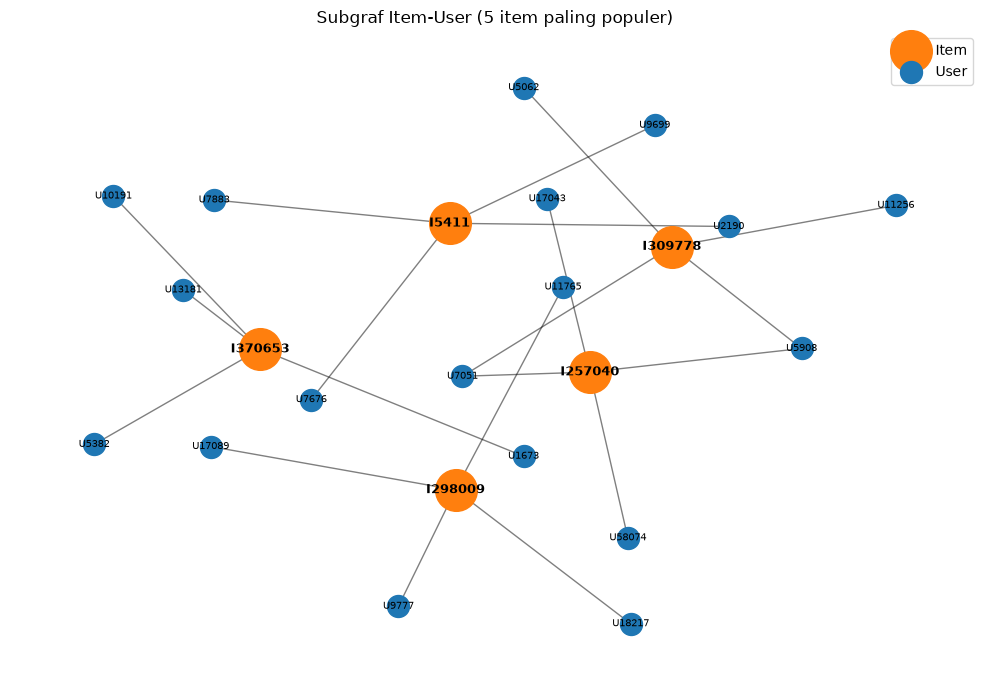

Jumlah simpul: 23 | Jumlah sisi: 20

=== Informasi simpul User di grafik ===
Jumlah user di gambar : 18
User dengan 1 item    : 16
User dengan >=2 item  : 2
User penghubung antar item: {'U5908': 2, 'U7051': 2}


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

top_items = agg["itemid"].value_counts().head(5).index
sub = agg[agg["itemid"].isin(top_items)]
sub = sub.groupby("itemid").head(4)

G = nx.Graph()
for _, r in sub.iterrows():
    G.add_edge(f"I{int(r.itemid)}", f"U{int(r.visitorid)}")

item_nodes = [n for n in G if n.startswith("I")]
user_nodes = [n for n in G if n.startswith("U")]

pos = nx.spring_layout(G, seed=42, k=0.8)
plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=900, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:blue", node_size=250, label="User")
nx.draw_networkx_edges(G, pos, alpha=0.5)

# Label ID item dan ID user
nx.draw_networkx_labels(G, pos, labels={n: n for n in item_nodes}, font_size=9, font_weight="bold")
nx.draw_networkx_labels(G, pos, labels={n: n for n in user_nodes}, font_size=7)

plt.legend(scatterpoints=1)
plt.title("Subgraf Item-User (5 item paling populer)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul:", G.number_of_nodes(), "| Jumlah sisi:", G.number_of_edges())

derajat_user = {n: G.degree(n) for n in user_nodes}
print("\n=== Informasi simpul User di grafik ===")
print("Jumlah user di gambar :", len(user_nodes))
print("User dengan 1 item    :", sum(1 for d in derajat_user.values() if d == 1))
print("User dengan >=2 item  :", sum(1 for d in derajat_user.values() if d >= 2))
print("User penghubung antar item:", {k: v for k, v in derajat_user.items() if v >= 2})

5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

items = agg["itemid"].astype("category")
visitors = agg["visitorid"].astype("category")

X_item = csr_matrix(
    (agg["interaction_count"], (items.cat.codes, visitors.cat.codes)),
    shape=(items.cat.categories.size, visitors.cat.categories.size)
)

n_item, n_user = X_item.shape
user_per_item = np.diff(X_item.indptr)  

print("KARAKTERISTIK MATRIKS VSM SIMPUL ITEM (P1)")
print(f"• Shape (Item x User)         : {X_item.shape}")
print(f"  - Jumlah baris (Item)       : {n_item:,}")
print(f"  - Jumlah kolom (Visitor)    : {n_user:,}")
print(f"• Dimensi ruang vektor        : {n_user:,}")
print(f"• Elemen non-zero             : {X_item.nnz:,}")
print(f"• Total raw interaksi         : {int(X_item.sum()):,}")
print(f"• Sparsity                    : {1 - X_item.nnz / (n_item * n_user):.4%}")
print(f"• Rata-rata visitor/item      : {user_per_item.mean():.2f}")
print(f"• Median visitor/item         : {int(np.median(user_per_item))}")
print(f"• Maks visitor/item           : {user_per_item.max()}")
print(f"• Nilai maksimum sel          : {int(X_item.max())}")

item_ids = items.cat.categories
contoh = item_ids[user_per_item.argmax()]
vec = agg[agg["itemid"] == contoh].set_index("visitorid")["interaction_count"]
print(f"\nContoh vektor VSM item '{contoh}': {len(vec)} non-zero dari {n_user:,} dimensi")
print(vec.head())

KARAKTERISTIK MATRIKS VSM SIMPUL ITEM (P1)
• Shape (Item x User)         : (96004, 218017)
  - Jumlah baris (Item)       : 96,004
  - Jumlah kolom (Visitor)    : 218,017
• Dimensi ruang vektor        : 218,017
• Elemen non-zero             : 324,781
• Total raw interaksi         : 419,515
• Sparsity                    : 99.9984%
• Rata-rata visitor/item      : 3.38
• Median visitor/item         : 1
• Maks visitor/item           : 695
• Nilai maksimum sel          : 180

Contoh vektor VSM item '5411': 695 non-zero dari 218,017 dimensi
visitorid
2190     1
7676     1
7883     2
9699     1
11268    1
Name: interaction_count, dtype: int64


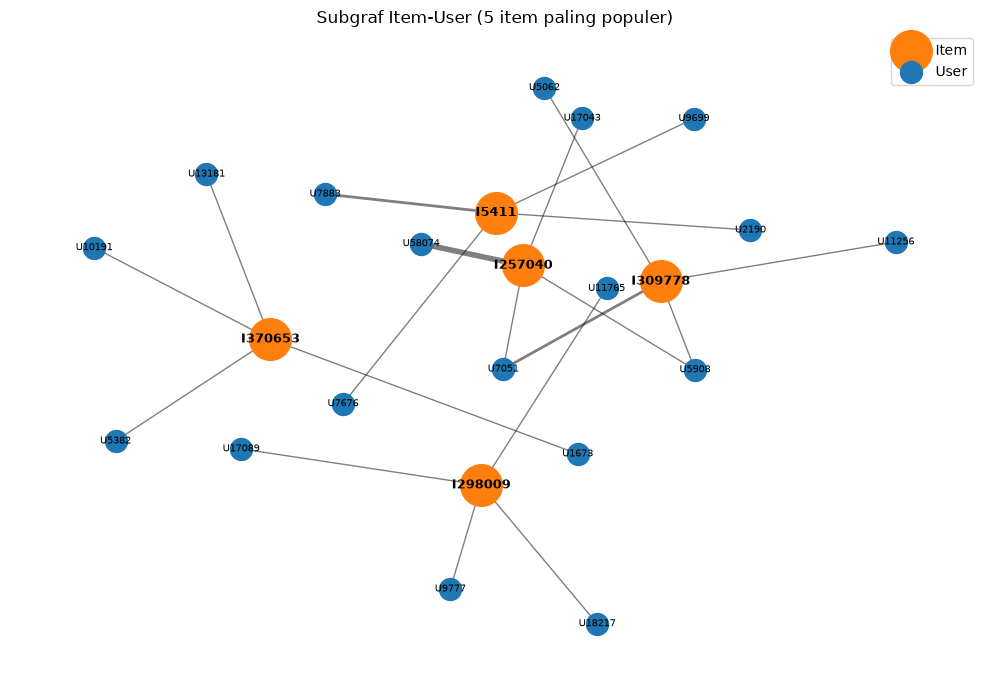

Jumlah simpul: 23 | Jumlah sisi: 20

=== Informasi simpul Item di grafik ===
Jumlah item di gambar : 5
Derajat tiap item     : {'I5411': 4, 'I257040': 4, 'I298009': 4, 'I309778': 4, 'I370653': 4}
Visitor total per item (seluruh P1): {'I5411': 695, 'I309778': 378, 'I370653': 260, 'I257040': 248, 'I298009': 242}


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

top_items = agg["itemid"].value_counts().head(5).index
sub = agg[agg["itemid"].isin(top_items)]
sub = sub.groupby("itemid").head(4)

G = nx.Graph()
for _, r in sub.iterrows():
    G.add_edge(f"I{int(r.itemid)}", f"U{int(r.visitorid)}", weight=int(r.interaction_count))

item_nodes = [n for n in G if n.startswith("I")]
user_nodes = [n for n in G if n.startswith("U")]

pos = nx.spring_layout(G, seed=42, k=0.8)
plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:orange", node_size=900, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:blue", node_size=250, label="User")
nx.draw_networkx_edges(G, pos, alpha=0.5, width=[G[u][v]["weight"] for u, v in G.edges])

nx.draw_networkx_labels(G, pos, labels={n: n for n in item_nodes}, font_size=9, font_weight="bold")
nx.draw_networkx_labels(G, pos, labels={n: n for n in user_nodes}, font_size=7)

plt.legend(scatterpoints=1)
plt.title("Subgraf Item-User (5 item paling populer)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul:", G.number_of_nodes(), "| Jumlah sisi:", G.number_of_edges())

# Informasi simpul Item di grafik
derajat_item = {n: G.degree(n) for n in item_nodes}
print("\n=== Informasi simpul Item di grafik ===")
print("Jumlah item di gambar :", len(item_nodes))
print("Derajat tiap item     :", derajat_item)
print("Visitor total per item (seluruh P1):",
      {f"I{int(i)}": int((agg['itemid'] == i).sum()) for i in top_items})

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)! 

Lebih efisien item karena simpulnya hanya 96.004, sedangkan User 218.017 (2,27× lebih sedikit), sehingga perhitungan similarity jauh lebih ringan dan efisiem. Item hub seperti 5411 (695 visitor) juga akan meledakkan jumlah pasangan di proyeksi User-User. dan juga Lebih efektif: vektor item lebih kaya (rata-rata 3,38 visitor/item), sedangkan vektor user hanya 1,49 item/user sehingga rawan cold-start dan similarity-nya kurang stabil.



7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

p1 = pd.read_csv("events_p1_training.csv")
agg = (p1.groupby(["itemid", "visitorid"]).size()
         .reset_index(name="interaction_count"))

items = agg["itemid"].astype("category")
visitors = agg["visitorid"].astype("category")
item_ids = items.cat.categories

X_item = csr_matrix(
    (agg["interaction_count"], (items.cat.codes, visitors.cat.codes)),
    shape=(len(item_ids), len(visitors.cat.categories)),
)
user_per_item = np.diff(X_item.indptr)

Xn = normalize(X_item, norm="l2", axis=1)

rng = np.random.default_rng(42)
kandidat = np.where(user_per_item >= 10)[0]
ref_idx = int(rng.choice(kandidat))
ref_item = int(item_ids[ref_idx])

sims = (Xn @ Xn[ref_idx].T).toarray().ravel()
sims[ref_idx] = np.nan          

print(f"Item acuan        : {ref_item} ({user_per_item[ref_idx]} visitor)")
print(f"Jumlah item dibandingkan: {np.sum(~np.isnan(sims)):,}")
print(f"Item dengan cosine > 0 : {np.sum(sims > 0):,}")
print("\nRingkasan distribusi cosine:")
print(pd.Series(sims).describe().round(4))

Item acuan        : 44208 (33 visitor)
Jumlah item dibandingkan: 96,003
Item dengan cosine > 0 : 80

Ringkasan distribusi cosine:
count    96003.0000
mean         0.0001
std          0.0029
min          0.0000
25%          0.0000
50%          0.0000
75%          0.0000
max          0.3178
dtype: float64


7 (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri
record acuannya)!

MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS tetangga, r.score AS cosine
ORDER BY cosine DESC
LIMIT 5

Query mengambil item acuan beserta item-item yang terhubung lewat relasi SIMILAR_TO, lalu mengurutkannya dari skor cosine tertinggi (ORDER BY cosine DESC) dan membatasi hasil 5 teratas (LIMIT 5).

In [ ]:
from neo4j import GraphDatabase

rows = [{"itemId": int(r.itemId), "cosine": float(r.cosine)} for r in top5.itertuples()]

with GraphDatabase.driver(uri, auth=(user, password)) as drv:
    drv.execute_query("""
        MATCH (a:Item {itemId: $ref})
        UNWIND $rows AS row
        MATCH (b:Item {itemId: row.itemId})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.score = row.cosine
    """, ref=ref_item, rows=rows, database_="neo4j")

    records, _, _ = drv.execute_query("""
        MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
        RETURN a.itemId AS acuan, b.itemId AS tetangga, r.score AS cosine
        ORDER BY cosine DESC
    """, ref=ref_item, database_="neo4j")

hasil = pd.DataFrame([r.data() for r in records])
hasil

,acuan,tetangga,cosine
0,44208,268897,0.339683
1,44208,345004,0.317800
2,44208,117984,0.314000
3,44208,176113,0.288000
4,44208,135609,0.229500
5,44208,361463,0.190500


7 (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

MATCH (a:Item {itemId: $ref})
UNWIND $rows AS row
MATCH (b:Item {itemId: row.itemId})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = row.cosine

MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS tetangga, r.score AS cosine
ORDER BY cosine DESC

Query mengambil item acuan a, lalu untuk tiap item mirip b dari daftar rows (hasil top 5 Python) ia membuat relasi SIMILAR_TO (MERGE, jadi tidak ganda jika dijalankan ulang) dan menyimpan nilai cosine sebagai properti score (SET).

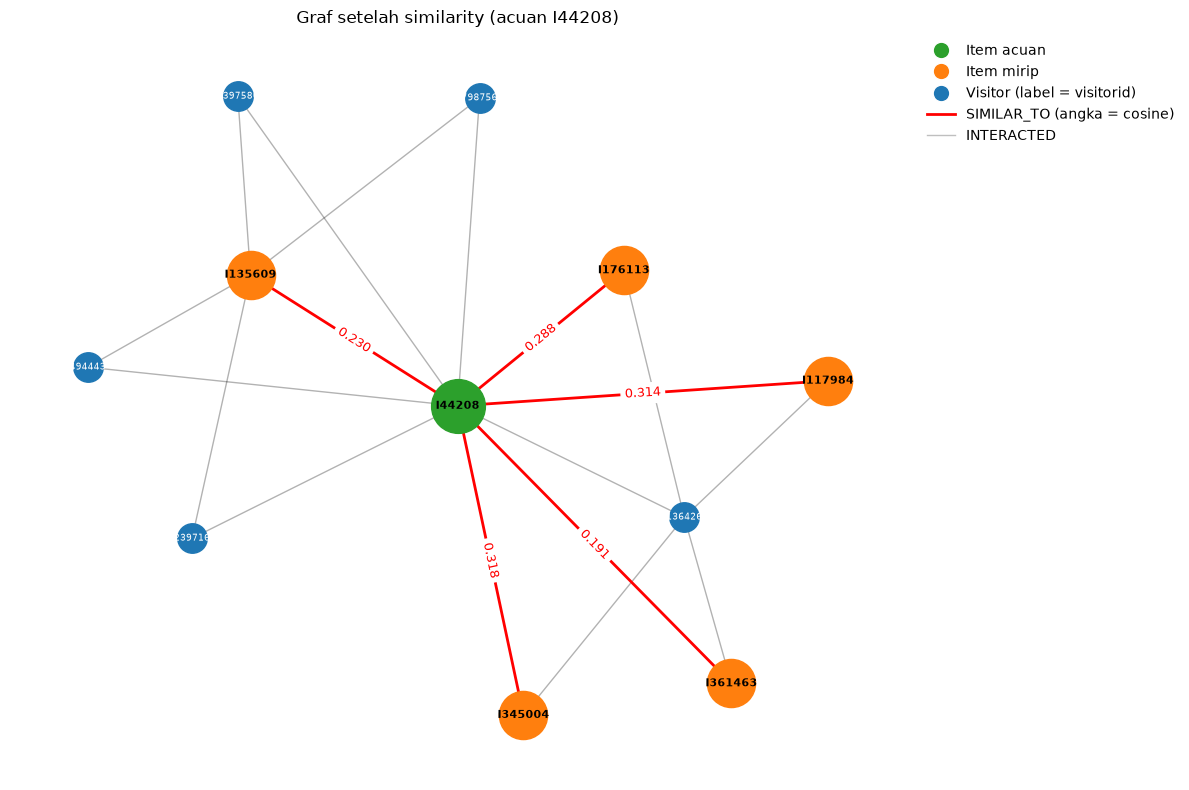

In [ ]:
from matplotlib.lines import Line2D

item_n = [f"I{i}" for i in nodes_item]
user_n = [n for n in G if n.startswith("U")]
sim_e = [(u, v) for u, v, d in G.edges(data=True) if d["jenis"] == "SIMILAR_TO"]
int_e = [(u, v) for u, v, d in G.edges(data=True) if d["jenis"] == "INTERACTED"]

pos = nx.spring_layout(G, seed=42, k=0.9)

fig, ax = plt.subplots(figsize=(12, 8))
nx.draw_networkx_nodes(G, pos, nodelist=user_n, node_color="tab:blue", node_size=450, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[f"I{ref_item}"], node_color="tab:green", node_size=1500, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=item_n[1:], node_color="tab:orange", node_size=1200, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=int_e, alpha=0.3, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=sim_e, edge_color="red", width=2, ax=ax)
nx.draw_networkx_edge_labels(
    G, pos, ax=ax, font_color="red", font_size=9,
    edge_labels={(u, v): f"{G[u][v]['score']:.3f}" for u, v in sim_e},
)

nx.draw_networkx_labels(G, pos, labels={n: n for n in item_n}, font_size=8, font_weight="bold", ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: n[1:] for n in user_n}, font_size=6.5,
                        font_color="white", ax=ax)

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:green",  markersize=12, label="Item acuan"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:orange", markersize=12, label="Item mirip"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue",   markersize=12, label="Visitor (label = visitorid)"),
    Line2D([0], [0], color="red",  lw=2, label="SIMILAR_TO (angka = cosine)"),
    Line2D([0], [0], color="gray", lw=1, alpha=0.5, label="INTERACTED"),
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)

ax.set_title(f"Graf setelah similarity (acuan I{ref_item})")
ax.axis("off")
plt.tight_layout()
plt.show()

8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah
perhitungan similarity!

SEBELUM: hanya interaksi
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN $ids
RETURN v.visitorId, type(r), i.itemId

SESUDAH: ditambah SIMILAR_TO
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId, b.itemId, s.score

Sebelum similarity, graf hanya berisi relasi interaksi Visitor-Item, sehingga item-item terhubung tidak langsung lewat visitor yang sama (SIMILAR_TO = 0). Sesudah similarity, graf ditambah 5 relasi SIMILAR_TO (garis merah) dari item acuan (hijau) ke 5 item paling mirip (oranye), dengan angka pada garis sebagai nilai cosine. Jumlah simpul tetap, sedangkan jumlah sisi naik dari menjadi (+5) karena penambahan sisi simmilarity.

SEBELUM -> simpul: 11 | sisi: 13 | SIMILAR_TO: 0
SESUDAH -> simpul: 11 | sisi: 18 | SIMILAR_TO: 5


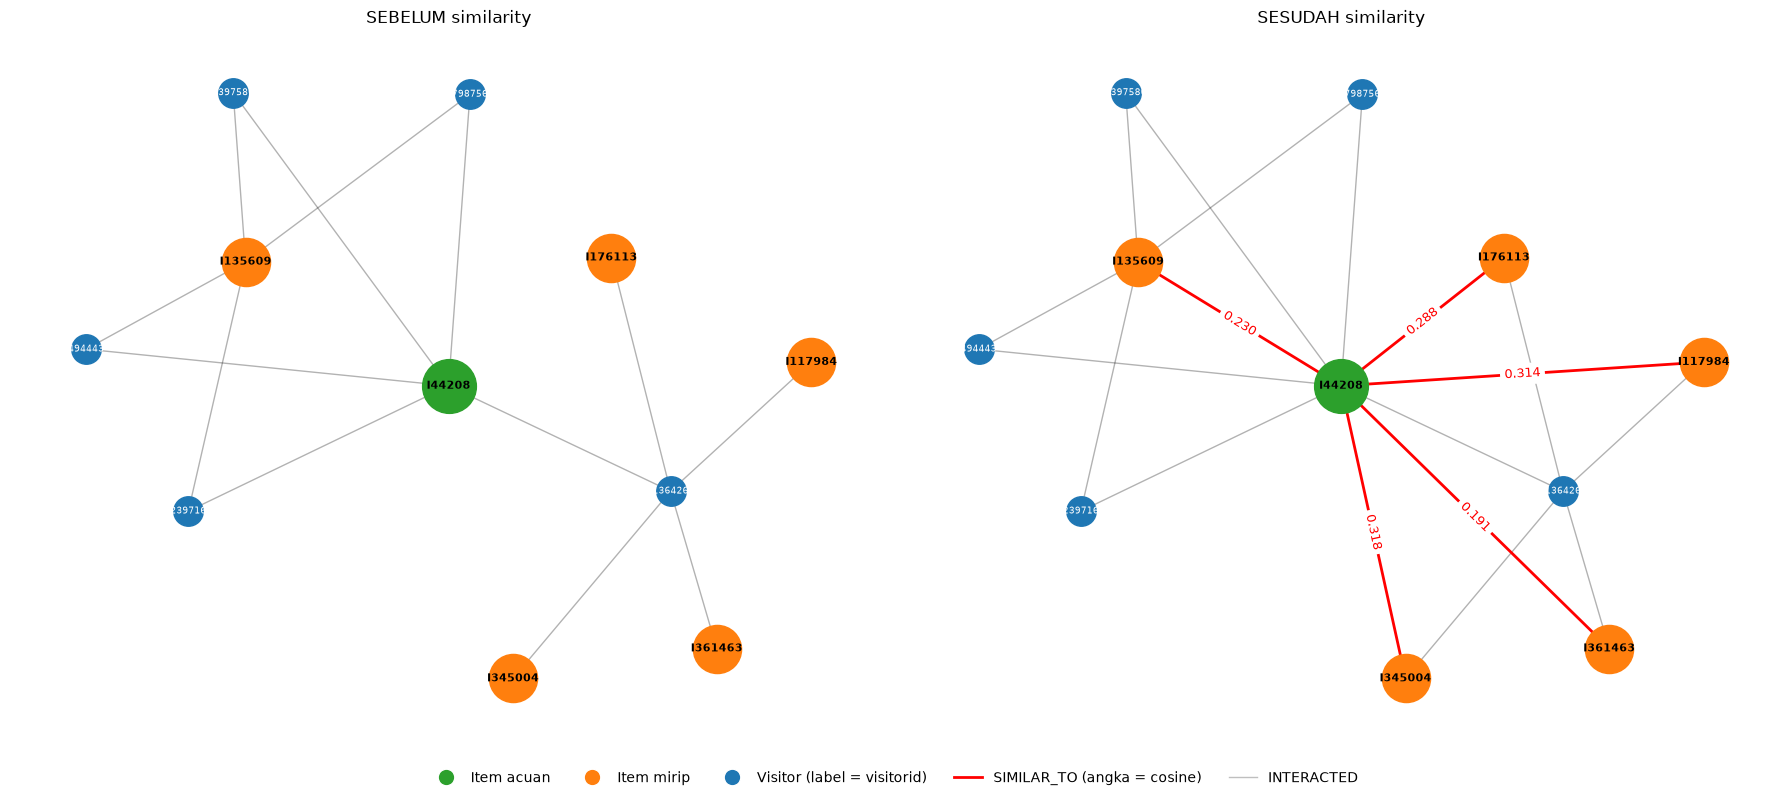

In [ ]:
G_before = G.copy()
G_before.remove_edges_from([(u, v) for u, v, d in G.edges(data=True) if d["jenis"] == "SIMILAR_TO"])

def n_sim(g):
    return sum(1 for _, _, d in g.edges(data=True) if d["jenis"] == "SIMILAR_TO")

print(f"SEBELUM -> simpul: {G_before.number_of_nodes()} | sisi: {G_before.number_of_edges()} | SIMILAR_TO: {n_sim(G_before)}")
print(f"SESUDAH -> simpul: {G.number_of_nodes()} | sisi: {G.number_of_edges()} | SIMILAR_TO: {n_sim(G)}")

item_n = [f"I{i}" for i in nodes_item]
user_n = [n for n in G if n.startswith("U")]
pos = nx.spring_layout(G, seed=42, k=0.9)      

def gambar(ax, g, judul):
    sim_e = [(u, v) for u, v, d in g.edges(data=True) if d["jenis"] == "SIMILAR_TO"]
    int_e = [(u, v) for u, v, d in g.edges(data=True) if d["jenis"] == "INTERACTED"]
    nx.draw_networkx_nodes(g, pos, nodelist=user_n, node_color="tab:blue", node_size=450, ax=ax)
    nx.draw_networkx_nodes(g, pos, nodelist=[f"I{ref_item}"], node_color="tab:green", node_size=1500, ax=ax)
    nx.draw_networkx_nodes(g, pos, nodelist=item_n[1:], node_color="tab:orange", node_size=1200, ax=ax)
    nx.draw_networkx_edges(g, pos, edgelist=int_e, alpha=0.3, ax=ax)
    if sim_e:
        nx.draw_networkx_edges(g, pos, edgelist=sim_e, edge_color="red", width=2, ax=ax)
        nx.draw_networkx_edge_labels(g, pos, ax=ax, font_color="red", font_size=9,
            edge_labels={(u, v): f"{g[u][v]['score']:.3f}" for u, v in sim_e})
    nx.draw_networkx_labels(g, pos, labels={n: n for n in item_n}, font_size=8, font_weight="bold", ax=ax)
    nx.draw_networkx_labels(g, pos, labels={n: n[1:] for n in user_n}, font_size=6.5, font_color="white", ax=ax)
    ax.set_title(judul)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
gambar(axes[0], G_before, f"SEBELUM similarity")
gambar(axes[1], G, f"SESUDAH similarity")

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:green",  markersize=12, label="Item acuan"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:orange", markersize=12, label="Item mirip"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue",   markersize=12, label="Visitor (label = visitorid)"),
    Line2D([0], [0], color="red",  lw=2, label="SIMILAR_TO (angka = cosine)"),
    Line2D([0], [0], color="gray", lw=1, alpha=0.5, label="INTERACTED"),
]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

2.2 Analytics 

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

Penyaringan Hanya dengan user yang punya ≥ 3 item di P1 dan ≥ 1 item baru di P2 yang di-cart atau dibeli. yang menghasilkan 116 user (pool). karena jika user tanpa riwayat tidak bisa dicari tetangganya, dan user tanpa kunci jawaban tidak bisa dihitung Hit@5 dan NDCG@5-nya.

In [246]:
import numpy as np, pandas as pd

p1 = pd.read_csv("events_p1_training.csv")
p2 = pd.read_csv("events_p2_testing.csv")

# Jumlah item unik per user di P1
item_p1 = p1.groupby("visitorid")["itemid"].nunique().rename("item_P1")

# Item di P2 yang BELUM pernah disentuh user itu di P1
p1_pairs = p1[["visitorid", "itemid"]].drop_duplicates().assign(seen=1)
p2m = p2[["visitorid", "itemid", "event"]].merge(p1_pairs, on=["visitorid", "itemid"], how="left")
p2_baru = p2m[p2m["seen"].isna()]

baru_semua = p2_baru.groupby("visitorid")["itemid"].nunique().rename("item_baru_P2")
baru_kuat = (p2_baru[p2_baru["event"].isin(["addtocart", "transaction"])]
             .groupby("visitorid")["itemid"].nunique().rename("baru_cart_beli_P2"))

tabel = (item_p1.to_frame().join(baru_semua, how="inner")
         .join(baru_kuat, how="left").fillna(0).astype(int))

# Populasi layak uji
tier_a = tabel[(tabel["item_P1"] >= 3) & (tabel["item_baru_P2"] >= 1)]
tier_b = tier_a[tier_a["baru_cart_beli_P2"] >= 1]
pool = tier_b if len(tier_b) > 0 else tier_a

print(f"User di P1 dan P2 (ada item baru)            : {len(tabel):,}")
print(f"Tier A (>=3 item P1, >=1 item baru P2)       : {len(tier_a):,}")
print(f"Tier B (A + >=1 item baru di-cart/dibeli P2) : {len(tier_b):,}")
print(f"Pool dipakai: {'B' if len(tier_b) > 0 else 'A'} ({len(pool):,} user)")

pool_tampil = pool.sort_index()      
with pd.option_context("display.max_rows", None):
    display(pool_tampil)

print(f"Jumlah user di pool: {len(pool_tampil)}")

User di P1 dan P2 (ada item baru)            : 6,399
Tier A (>=3 item P1, >=1 item baru P2)       : 1,509
Tier B (A + >=1 item baru di-cart/dibeli P2) : 116
Pool dipakai: B (116 user)


,item_P1,item_baru_P2,baru_cart_beli_P2
visitorid,,,
6958,5,42,16
11333,10,10,1
12579,23,32,12
23076,9,8,2
23460,4,1,1
26912,5,11,2
33682,4,1,1
72363,3,5,4
93466,7,7,1


Jumlah user di pool: 116


Memilih 1 user secara acak dengan np.random.default_rng(SEED).choice(kandidat). dengan nilai speed 42

In [260]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

SEED = 42

agg = (p1.groupby(["itemid", "visitorid"]).size()
         .reset_index(name="interaction_count"))

u_cat = agg["visitorid"].astype("category")
i_cat = agg["itemid"].astype("category")
user_ids, item_ids_u = u_cat.cat.categories, i_cat.cat.categories

X_user = csr_matrix(
    (agg["interaction_count"], (u_cat.cat.codes, i_cat.cat.codes)),
    shape=(len(user_ids), len(item_ids_u)),
)
item_per_user = np.diff(X_user.indptr)
Xn_user = normalize(X_user, norm="l2", axis=1)

kandidat = np.where(np.isin(user_ids, pool.index.values))[0]
rng = np.random.default_rng(SEED)
u_idx = int(rng.choice(kandidat))
target_user = int(user_ids[u_idx])

print(f"Kandidat User     : {len(kandidat):,}")
print(f"User terpilih     : {target_user}")
print(f"item_P1           : {tabel.loc[target_user, 'item_P1']}")
print(f"item_baru_P2      : {tabel.loc[target_user, 'item_baru_P2']}")
print(f"baru_cart_beli_P2 : {tabel.loc[target_user, 'baru_cart_beli_P2']}")

def knn_recommend(u_idx, k=5, top_n=5):
    sims = (Xn_user @ Xn_user[u_idx].T).toarray().ravel()
    sims[u_idx] = -1
    nn = np.argsort(-sims, kind="stable")[:k]

    B = (X_user[nn] > 0).astype(float)
    skor = np.asarray(B.T @ sims[nn]).ravel()
    skor[X_user[u_idx].indices] = 0

    top = np.argsort(-skor, kind="stable")[:top_n]
    tetangga = pd.DataFrame({"visitorid": user_ids[nn].astype(int),
                             "cosine": sims[nn].round(4)})
    rekom = pd.DataFrame({"itemId": item_ids_u[top].astype(int),
                          "skor": skor[top].round(4)})
    return tetangga, rekom[rekom["skor"] > 0].reset_index(drop=True)

Kandidat User     : 116
User terpilih     : 101175
item_P1           : 30
item_baru_P2      : 39
baru_cart_beli_P2 : 9


(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

In [261]:
def knn_recommend(u_idx, k=5, top_n=5):
    sims = (Xn_user @ Xn_user[u_idx].T).toarray().ravel()
    sims[u_idx] = -1                                   
    nn = np.argsort(-sims, kind="stable")[:k]          

    Bn = (X_user[nn] > 0).astype(float)                
    skor = np.asarray(Bn.T @ sims[nn]).ravel()         
    skor[X_user[u_idx].indices] = 0                    

    # info tambahan buat penjelasan
    Bt = (X_user[u_idx] > 0).astype(int)
    item_sama = ((X_user[nn] > 0).astype(int) @ Bt.T).toarray().ravel()   

    top = np.argsort(-skor, kind="stable")[:top_n]
    tetangga = pd.DataFrame({
        "visitorid": user_ids[nn].astype(int),
        "cosine": sims[nn].round(4),
        "item_di_P1": item_per_user[nn],
        "item_sama_dgn_target": item_sama,
    })
    rekom = pd.DataFrame({
        "itemId": item_ids_u[top].astype(int),
        "skor": skor[top].round(4),
        "dipilih_n_tetangga": np.asarray(Bn[:, top].sum(axis=0)).ravel().astype(int),
    })
    return tetangga, rekom[rekom["skor"] > 0].reset_index(drop=True)


tetangga, rekom = knn_recommend(u_idx, k=5, top_n=5)

print(f"User target: {target_user} ({item_per_user[u_idx]} item di P1)")
print("\n5 tetangga terdekat (KNN, k=5):")
display(tetangga)

print("Peringkat item rekomendasi (belum disentuh target):")
display(rekom)

User target: 101175 (30 item di P1)

5 tetangga terdekat (KNN, k=5):


,visitorid,cosine,item_di_P1,item_sama_dgn_target
0,1083118,0.8571,1,1
1,700167,0.8316,2,1
2,313865,0.4949,3,1
3,1370521,0.3240,7,1
4,46997,0.2857,1,1


Peringkat item rekomendasi (belum disentuh target):


,itemId,skor,dipilih_n_tetangga
0,304253,0.8316,1
1,292352,0.4949,1
2,292543,0.4949,1
3,54939,0.3240,1
4,94105,0.3240,1


(b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [240]:
iklan = rekom.head(3)
print(f"3 item yang diiklankan ke user {target_user} (KNN, k=5):")
display(iklan)

3 item yang diiklankan ke user 101175 (KNN, k=5):


,itemId,skor,dipilih_n_tetangga
0,304253,0.8316,1
1,292352,0.4949,1
2,292543,0.4949,1


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah: 


In [241]:
K = 5
rek = rekom["itemId"].head(K).tolist()

p1_seen = set(p1.loc[p1["visitorid"] == target_user, "itemid"])
p2_u = p2[p2["visitorid"] == target_user]
relevan = set(
    p2_u.loc[p2_u["event"].isin(["addtocart", "transaction"]), "itemid"]
) - p1_seen

hit5 = int(any(i in relevan for i in rek[:K]))


dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rek[:K]) if i in relevan)
idcg = sum(1 / np.log2(r + 2) for r in range(min(len(relevan), K)))
ndcg5 = dcg / idcg if idcg > 0 else 0.0

print(f"User {target_user} | rekomendasi: {rek} | item relevan: {len(relevan)}")

detail = (p2_u[p2_u["itemid"].isin(relevan) & p2_u["event"].isin(["addtocart", "transaction"])]
          .groupby(["itemid", "event"]).size().unstack(fill_value=0))
display(detail)

User 101175 | rekomendasi: [304253, 292352, 292543, 54939, 94105] | item relevan: 9


event,addtocart,transaction
itemid,,
31591,1,1
91086,1,1
98374,1,2
158575,1,2
285637,1,2
288887,1,2
316239,1,1
415020,1,1
446102,2,1


(a) Hit@5 

In [242]:
print(f"Hit@5  = {hit5}")

Hit@5  = 0


(b) NDCG@5

In [ ]:
print(f"NDCG@5 = {ndcg5:.4f}")

NDCG@5 = 0.0000
